In [3]:
#import libraries

import sys
sys.path.append('../')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

#metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve)

import warnings
warnings.filterwarnings('ignore')

from src.data_preprocessing import DataPreprocessor

print("All libraries imported successfully")

All libraries imported successfully


### 2. Load and Preprocess Data

In [7]:
preprocessor = DataPreprocessor()

df = preprocessor.load_data('../data/telco_comm_churn.csv')


Loading data from ../data/telco_comm_churn.csv...
Dataset loaded successfully: (7043, 21)


In [8]:
X_train, X_test, y_train, y_test = preprocessor.prepare_data(df)


STARTING DATA PREPROCESSING PIPELINE

Train-Test Split:
   Training samples: 5634
   Testing samples: 1409

Handling missing values...
   tenure: filled missing values with median 29.00
   MonthlyCharges: filled missing values with median 70.50
   TotalCharges: filled missing values with median 1398.12
Missing value handling completed.

Performing feature engineering...
Created 3 new features:
   tenure_group: [2 1 0 3]
   avg_monthly_per_tenure: 13.83 - 121.40
   num_services: 1 - 6

Performing feature engineering...
Created 3 new features:
   tenure_group: [3 0 2 1]
   avg_monthly_per_tenure: 13.78 - 118.59
   num_services: 1 - 6
   Encoded MultipleLines: 3 categories
   Encoded InternetService: 3 categories
   Encoded OnlineSecurity: 3 categories
   Encoded OnlineBackup: 3 categories
   Encoded DeviceProtection: 3 categories
   Encoded TechSupport: 3 categories
   Encoded StreamingTV: 3 categories
   Encoded StreamingMovies: 3 categories
   Encoded Contract: 3 categories
   Encoded

In [9]:
print(f"\n📊 Final Dataset Summary:")
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")
print(f"Churn rate (train): {y_train.mean()*100:.2f}%")
print(f"Churn rate (test): {y_test.mean()*100:.2f}%")


📊 Final Dataset Summary:
Training samples: 5634
Test samples: 1409
Number of features: 22
Churn rate (train): 26.54%
Churn rate (test): 26.54%


## Model Training

In [10]:

models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree' : DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest' : RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state = 42),
    'XGBoost' : XGBClassifier(n_estimators = 100, max_depth = 5, random_state=42, eval_metric ='logloss')    
}
models


{'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
 'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
 'Random Forest': RandomForestClassifier(max_depth=10, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='logloss',
               feature_types=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=None, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=100,
      

In [11]:

# train all models
results = {}

print("\nTRAINING STARTED!!!!")

for name, model in models.items():
    print(f"\nTraining started for {name}...")
    #train
    model.fit(X_train, y_train)
    
    #predict
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:,1]
    
    #calculate Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    
    
    #store the result
    results[name] = {
        'model' : model,
        'accuracy' : accuracy,
        'precision' : precision,
        'recall':recall,
        'f1' : f1, 
        'roc_auc': roc_auc,
        'y_pred' : y_pred,
        'y_pred_proba': y_pred_proba
    }
    
    
    print(f"{name} trained")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"ROC AUC : {roc_auc:.4f}")
    
    
print("\nTRAINING COMPLETED!!!!")


TRAINING STARTED!!!!

Training started for Logistic Regression...
Logistic Regression trained
Accuracy: 0.7956
ROC AUC : 0.8391

Training started for Decision Tree...
Decision Tree trained
Accuracy: 0.7686
ROC AUC : 0.7442

Training started for Random Forest...
Random Forest trained
Accuracy: 0.7999
ROC AUC : 0.8384

Training started for Gradient Boosting...
Gradient Boosting trained
Accuracy: 0.8055
ROC AUC : 0.8450

Training started for XGBoost...
XGBoost trained
Accuracy: 0.7821
ROC AUC : 0.8252

TRAINING COMPLETED!!!!


In [12]:

# model comparison

model_compare = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results],
    'Precision': [results[m]['precision'] for m in results],
    'F1-Score': [results[m]['f1'] for m in results],
    'ROC-AUC': [results[m]['roc_auc'] for m in results],
    'Recall': [results[m]['recall'] for m in results],
    
})

model_compare

,Model,Accuracy,Precision,F1-Score,ROC-AUC,Recall
0,Logistic Regression,0.795600,0.636076,0.582609,0.839092,0.537433
1,Decision Tree,0.768630,0.570175,0.544693,0.744195,0.521390
2,Random Forest,0.799858,0.663121,0.570122,0.838442,0.500000
3,Gradient Boosting,0.805536,0.674825,0.584848,0.844966,0.516043
4,XGBoost,0.782115,0.614334,0.539730,0.825242,0.481283


In [13]:

model_compare = model_compare.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

In [14]:
print(model_compare.to_string(index=False))

              Model  Accuracy  Precision  F1-Score  ROC-AUC   Recall
  Gradient Boosting  0.805536   0.674825  0.584848 0.844966 0.516043
Logistic Regression  0.795600   0.636076  0.582609 0.839092 0.537433
      Random Forest  0.799858   0.663121  0.570122 0.838442 0.500000
            XGBoost  0.782115   0.614334  0.539730 0.825242 0.481283
      Decision Tree  0.768630   0.570175  0.544693 0.744195 0.521390


In [15]:
#save the compariosn in excel form
model_compare.to_csv('../reports/model_comparison.csv', index = False)
print("Saved: Model compariosn file in reports")

Saved: Model compariosn file in reports


## Model Visualisation

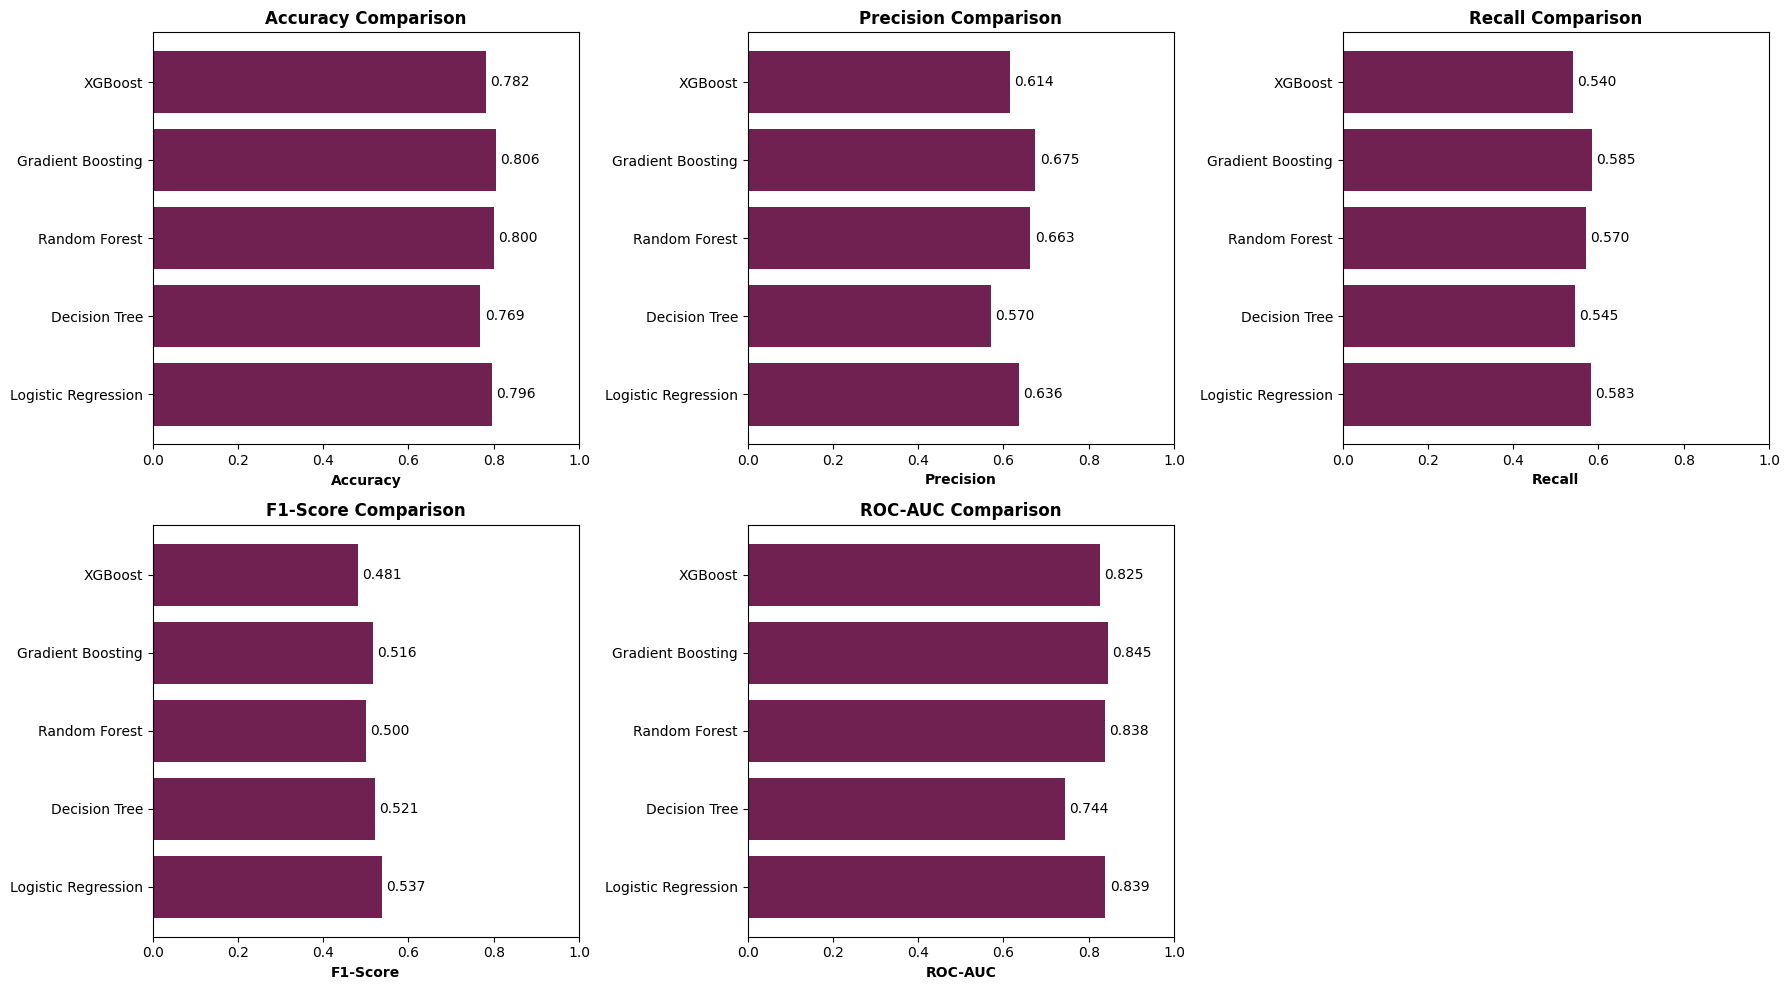

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18,10))
axes = axes.flatten()

metrics = ['accuracy', 'precision', 'f1', 'recall', 'roc_auc']
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

for idx, (metric, metric_name) in enumerate(zip(metrics, metrics_names)):
    
    values = [results[m][metric] for m in results]
    model_names = list(results.keys())
    
    axes[idx].barh(model_names, values, color="#702152")
    axes[idx].set_xlabel(metric_name, fontweight = 'bold')
    axes[idx].set_xlim(0,1)
    axes[idx].set_title(f'{metric_name} Comparison', fontweight = 'bold')
    

    
    for i, v in enumerate(values):
        axes[idx].text(v + 0.01, i, f'{v:.3f}', va='center')
    
    
    
    
    
fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig('../reports/model_comparison_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
best_model_name = model_compare.iloc[0]['Model']
best_model_result = results[best_model_name]

# best_model_name, best_model_result

print(f"Best Model : {best_model_name}")

Best Model : Gradient Boosting


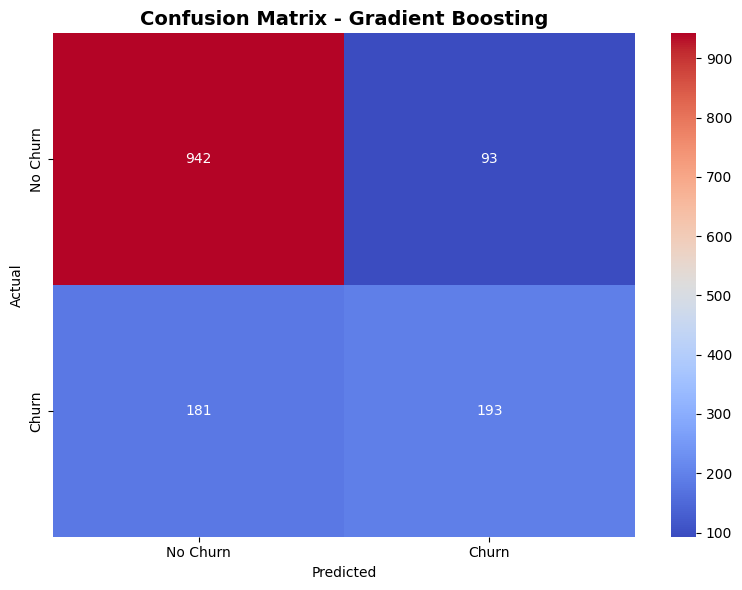

✅ Saved: reports/confusion_matrix.png


In [18]:
cm = confusion_matrix(y_test, best_model_result['y_pred'])

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])

plt.title(f'Confusion Matrix - {best_model_name}', fontsize=14, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')


plt.tight_layout()
plt.savefig('../reports/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Saved: reports/confusion_matrix.png")

In [19]:
print(classification_report(y_test, best_model_result['y_pred'],
                            target_names = ['No Chrun', 'Churn']))

              precision    recall  f1-score   support

    No Chrun       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.58       374

    accuracy                           0.81      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.80      0.81      0.80      1409



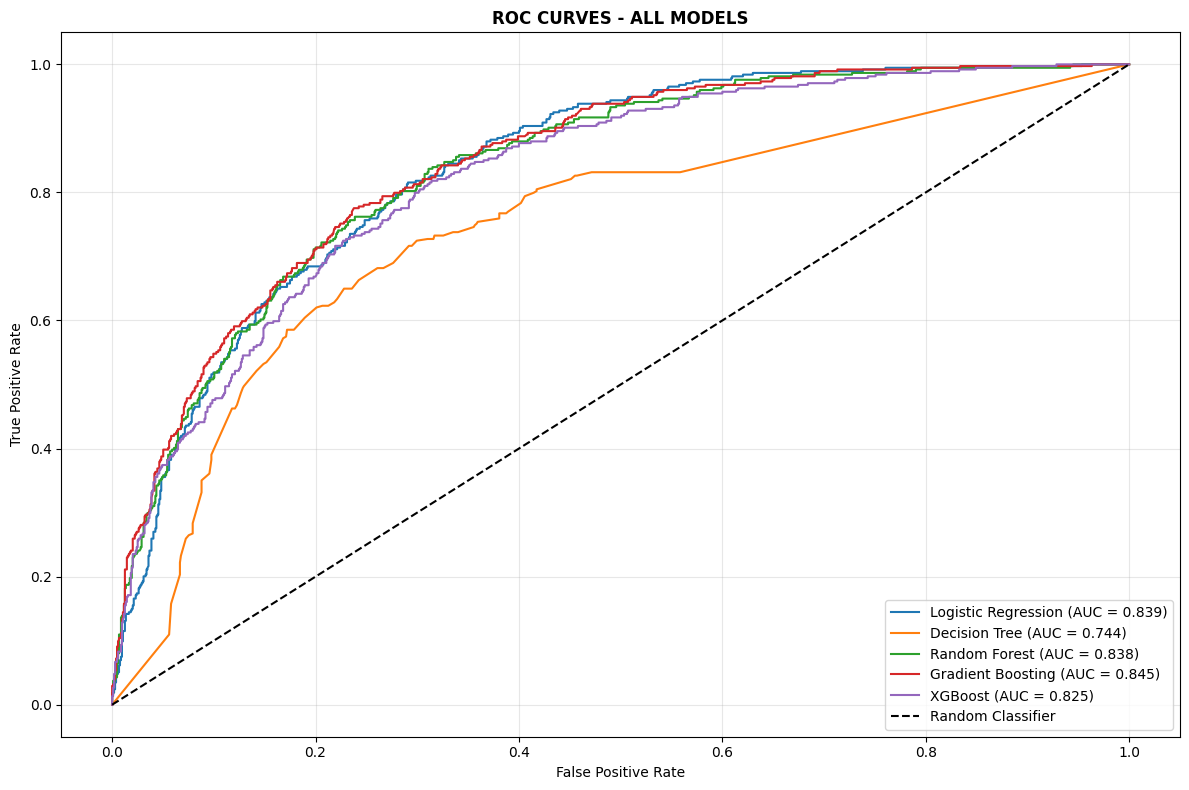

In [20]:
plt.figure(figsize=(12,8))

for name in results:
    fpr, tpr, _ = roc_curve(y_test, results[name]['y_pred_proba'])
    plt.plot(fpr, tpr, label = f"{name} (AUC = {results[name]['roc_auc']:.3f})")
    
    
plt.plot([0,1], [0,1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC CURVES - ALL MODELS', fontweight = 'bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/roc_curves.png', dpi=300, bbox_inches='tight')

plt.show()

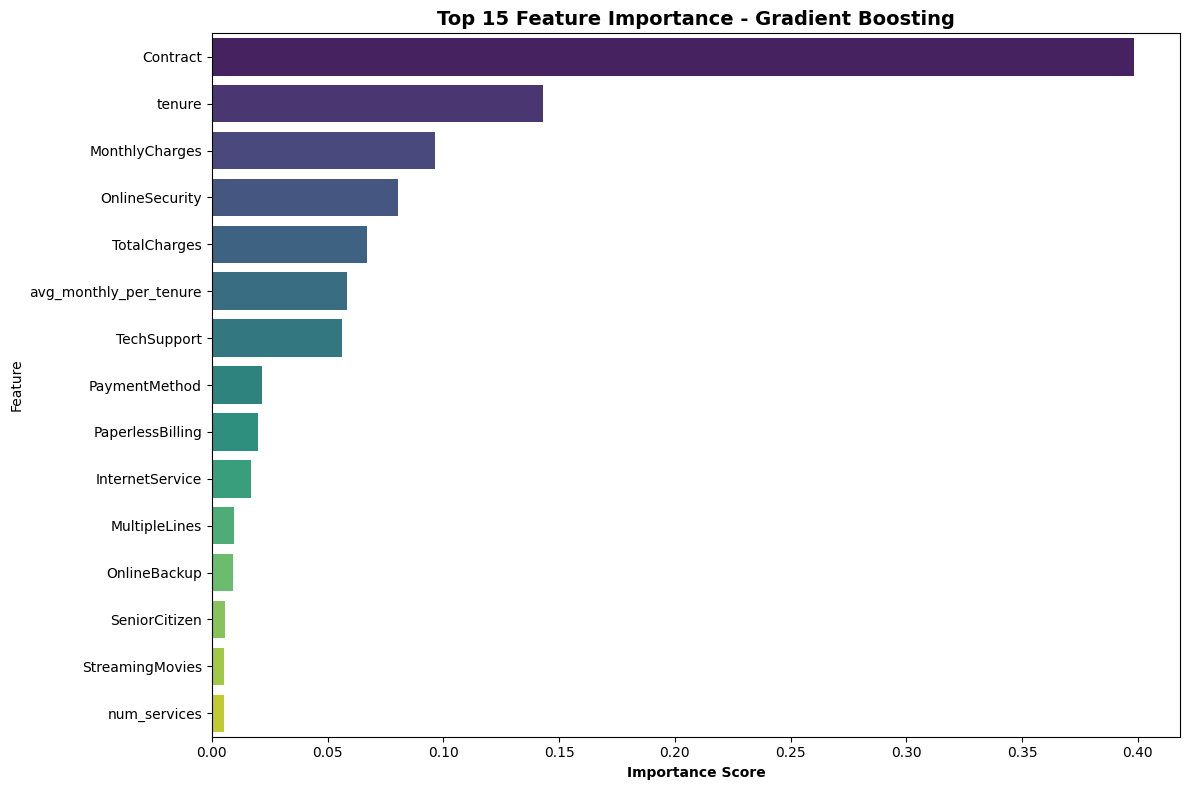

✅ Saved: reports/feature_importance.png

📊 Top 10 Most Important Features:
               Feature  Importance
              Contract    0.398324
                tenure    0.143147
        MonthlyCharges    0.096254
        OnlineSecurity    0.080352
          TotalCharges    0.067070
avg_monthly_per_tenure    0.058411
           TechSupport    0.056322
         PaymentMethod    0.021589
      PaperlessBilling    0.020174
       InternetService    0.016834


In [21]:
if hasattr(best_model_result['model'], 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': best_model_result['model'].feature_importances_
    }).sort_values('Importance', ascending=False).head(15)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(data=feature_importance, y='Feature', x='Importance', palette='viridis')
    plt.title(f'Top 15 Feature Importance - {best_model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Importance Score', fontweight='bold')
    plt.tight_layout()
    plt.savefig('../reports/feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✅ Saved: reports/feature_importance.png")
    print("\n📊 Top 10 Most Important Features:")
    print(feature_importance.head(10).to_string(index=False))
else:
    print(f"\n⚠️  {best_model_name} doesn't have feature_importances_ attribute")

In [23]:
import joblib

best_model = best_model_result['model']
model_path = f'../models/best_model_{best_model_name.replace(" ", "_").lower()}.pkl'

joblib.dump(best_model, model_path)
joblib.dump(preprocessor, '../models/preprocessor.pkl')
print("\n Model Saved")
print(f"Modle Path : {model_path}")


 Model Saved
Modle Path : ../models/best_model_gradient_boosting.pkl


In [24]:
# CELL 11: Final Summary
print("\n" + "="*60)
print("PROJECT SUMMARY")
print("="*60)
print(f"\n🎯 Best Model: {best_model_name}")
print(f"   ROC-AUC Score: {best_model_result['roc_auc']:.4f}")
print(f"   Accuracy: {best_model_result['accuracy']:.4f}")
print(f"   F1-Score: {best_model_result['f1']:.4f}")

print(f"\n📁 Generated Files:")
print("   - reports/model_comparison.csv")
print("   - reports/model_comparison_visual.png")
print("   - reports/confusion_matrix.png")
print("   - reports/roc_curves.png")
print("   - reports/feature_importance.png")
print("   - models/best_model_*.pkl")
print("   - models/preprocessor.pkl")

print("\n✅ PROJECT COMPLETE!")
print("="*60)


PROJECT SUMMARY

🎯 Best Model: Gradient Boosting
   ROC-AUC Score: 0.8450
   Accuracy: 0.8055
   F1-Score: 0.5848

📁 Generated Files:
   - reports/model_comparison.csv
   - reports/model_comparison_visual.png
   - reports/confusion_matrix.png
   - reports/roc_curves.png
   - reports/feature_importance.png
   - models/best_model_*.pkl
   - models/preprocessor.pkl

✅ PROJECT COMPLETE!
